In [1]:
import pandas as pd
import numpy as np
import re
import html

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
dataset = load_dataset("stanfordnlp/imdb")

df = pd.DataFrame({
    "text": dataset["train"]["text"],
    "label": dataset["train"]["label"]
})

df.head()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [5]:
label_map = {
    0: "negative",
    1: "positive"
}

df["label_name"] = df["label"].map(label_map)
df.head()

,text,label,label_name
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,negative
1,"""I Am Curious: Yellow"" is a risible and preten...",0,negative
2,If only to avoid making this type of film in t...,0,negative
3,This film was probably inspired by Godard's Ma...,0,negative
4,"Oh, brother...after hearing about this ridicul...",0,negative


In [6]:
df = df.sample(n=10000, random_state=42).reset_index(drop=True)
df.shape

(10000, 3)

In [7]:
df["label_name"].value_counts()

label_name
negative    5038
positive    4962
Name: count, dtype: int64

In [9]:
def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [10]:
df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,"Dumb is as dumb does, in this thoroughly unint...",dumb is as dumb does in this thoroughly uninte...
1,I dug out from my garage some old musicals and...,i dug out from my garage some old musicals and...
2,After watching this movie I was honestly disap...,after watching this movie i was honestly disap...
3,This movie was nominated for best picture but ...,this movie was nominated for best picture but ...
4,Just like Al Gore shook us up with his painful...,just like al gore shook us up with his painful...


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [13]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [14]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [15]:
y_pred = model.predict(X_test)

In [16]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.877


In [17]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["negative", "positive"]
))

              precision    recall  f1-score   support

    negative       0.90      0.85      0.88      1008
    positive       0.86      0.90      0.88       992

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



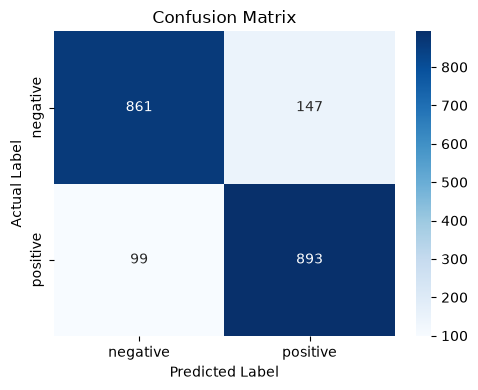

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["negative", "positive"],
    yticklabels=["negative", "positive"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
def predict_sentiment(text):
    cleaned = clean_text(text)

    prediction = model.predict([cleaned])[0]
    probabilities = model.predict_proba([cleaned])[0]

    if prediction == 1:
        label = "positive"
        confidence = probabilities[1]
    else:
        label = "negative"
        confidence = probabilities[0]

    return {
        "original_text": text,
        "cleaned_text": cleaned,
        "predicted_label": label,
        "confidence": float(confidence),
        "negative_probability": float(probabilities[0]),
        "positive_probability": float(probabilities[1])
    }

In [22]:
sample_reviews = [
    "Absolutely brilliant film. The acting, direction, and story were outstanding.",
    "This was a complete waste of time. Boring, confusing, and badly written.",
    "The movie had beautiful visuals but the plot was weak and predictable.",
    "One of the best movies I have seen this year. Highly recommended!",
    "Terrible experience. The characters were flat and the dialogue felt unnatural."
]

for review in sample_reviews:
    result = predict_sentiment(review)
    print("Review:", review)
    print("Prediction:", result["predicted_label"])
    print("Confidence:", round(result["confidence"], 4))
    print("-" * 80)

Review: Absolutely brilliant film. The acting, direction, and story were outstanding.
Prediction: positive
Confidence: 0.7069
--------------------------------------------------------------------------------
Review: This was a complete waste of time. Boring, confusing, and badly written.
Prediction: negative
Confidence: 0.967
--------------------------------------------------------------------------------
Review: The movie had beautiful visuals but the plot was weak and predictable.
Prediction: negative
Confidence: 0.7314
--------------------------------------------------------------------------------
Review: One of the best movies I have seen this year. Highly recommended!
Prediction: positive
Confidence: 0.9302
--------------------------------------------------------------------------------
Review: Terrible experience. The characters were flat and the dialogue felt unnatural.
Prediction: negative
Confidence: 0.8508
----------------------------------------------------------------------

In [21]:
import pickle

model_filename = "movie_sentiment_model.pkl"

with open(model_filename, "wb") as file:
    pickle.dump(model, file)